# Лабораторная работа 1
### Выполнил: Даулетов Максим Александрович

Добро пожаловать в лабораторную работу! 
Оформите ваше решение контеста Kaggle в соответствии с этим шаблоном. Ваша задача - показать проверяющим ход ваших рассуждений, поэтому советуем писать много комментариев к коду и приводить комментарии к логике на каждом этапе в текстовых ячейках. 
Где необходимо, используйте графики для большей наглядности.

При отправке поменяйте название файла на ваши ФИО!

### EDA (исследовательский анализ данных)

В этом разделе вам необходимо провести анализ вашего датасета, интерпретировать признаки, выяснить их значимость и исследовать зависимости между ними.

In [2]:

# exploratory data analysis
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

data = pd.read_csv('train.csv', index_col=0)
my_seed = 7185 # любое целое число на ваш выбор
random.seed(my_seed)
np.random.seed(my_seed)

In [2]:
data.head()

,carat,cut,color,clarity,depth,table,x,y,z,theta1,theta2,price
id,,,,,,,,,,,,
17044,0.28,Ideal,F,VVS2,61.6,55.0,4.22,4.26,2.61,5,5,612
30625,0.28,Ideal,I,VS1,62.5,54.0,4.18,4.23,2.63,5,6,448
17043,0.28,'Very Good',F,IF,62.2,55.0,4.23,4.26,NaN,5,7,612
37947,0.28,'Very Good',E,VS2,63.0,59.0,4.11,4.15,2.60,5,8,487
30626,0.28,Ideal,I,VS1,62.4,54.0,4.18,4.19,2.61,5,9,448


Сначала выясним, что значит каждый из признаков.  
carat - вес в специальных для драгоценных камней единицах.  
cut - качество огранки  
color - цвет алмаза  
clarity - чистота алмаза  
depth - процент глубины, вычисляемый как $\frac{2z}{x+y}$  
table - ширина верхней плоскости относительно самой широкой точки
x, y, z - измерения по длине, ширине и глубине
theta 1, theta 2 - не известно.
Теперь разделим признаки на две части - числовые и категориальные и начнем работать с числовыми.

In [3]:
categ_features = ['cut','color','clarity']
data_1 = data.drop(categ_features, axis=1, inplace=False)

In [4]:
num_features = ['carat','depth','table','x','y','z','theta1','theta2']
data_2 = data.drop(num_features, axis=1, inplace=False)

In [5]:
data_1.head()

,carat,depth,table,x,y,z,theta1,theta2,price
id,,,,,,,,,
17044,0.28,61.6,55.0,4.22,4.26,2.61,5,5,612
30625,0.28,62.5,54.0,4.18,4.23,2.63,5,6,448
17043,0.28,62.2,55.0,4.23,4.26,NaN,5,7,612
37947,0.28,63.0,59.0,4.11,4.15,2.60,5,8,487
30626,0.28,62.4,54.0,4.18,4.19,2.61,5,9,448


In [6]:
data_1.describe()

,carat,depth,table,x,y,z,theta1,theta2,price
count,40453.00000,40396.000000,40453.000000,40405.000000,40393.000000,40411.000000,40453.000000,40453.000000,40453.000000
mean,0.77475,61.755897,57.438563,5.704927,18.773722,3.523399,19.071738,19.036190,3736.247003
std,0.41728,1.425065,2.225439,1.033411,350.627591,0.656404,8.527417,8.570144,3615.804536
min,0.28000,43.000000,43.000000,0.000000,0.000000,0.000000,5.000000,5.000000,334.000000
25%,0.40000,61.100000,56.000000,4.740000,4.750000,2.930000,11.000000,11.000000,979.000000
50%,0.70000,61.800000,57.000000,5.700000,5.710000,3.520000,19.000000,19.000000,2401.000000
75%,1.03000,62.500000,59.000000,6.510000,6.510000,4.020000,27.000000,27.000000,5154.000000
max,2.02000,79.000000,79.000000,8.800000,9428.922353,31.800000,33.000000,33.000000,18803.000000


Добавим один столбец, в котором будут цены, сгруппированные по квантилям для удобства анализа зависимостей.

In [7]:
quantiles = data_1['price'].quantile([0.25, 0.5, 0.75])
data_1['price_quantile'] = pd.cut(data_1['price'], bins=[-float('inf'), quantiles[0.25], quantiles[0.5], quantiles[0.75], float('inf')], labels=[1,2,3,4])
data_1.groupby('price_quantile',observed=False).describe()

carat                                                    \
                  count      mean       std   min   25%   50%   75%   max   
price_quantile                                                              
1               10117.0  0.341546  0.045830  0.28  0.31  0.32  0.37  0.72   
2               10118.0  0.533583  0.122847  0.29  0.44  0.52  0.59  1.21   
3               10105.0  0.897808  0.169120  0.44  0.73  0.90  1.01  2.00   
4               10113.0  1.326453  0.292037  0.70  1.06  1.24  1.52  2.02   

                  depth             ... theta2          price               \
                  count       mean  ...    75%   max    count         mean   
price_quantile                      ...                                      
1               10105.0  61.778446  ...   27.0  33.0  10117.0   716.911832   
2               10101.0  61.679457  ...   27.0  33.0  10118.0  1588.441293   
3               10088.0  61.838927  ...   27.0  33.0  10105.0  3716.283424   
4               10102.0  61.726856  ...   27.0  33.0  10113.0  8925.591813   

                                                                       
                        std     min     25%     50%      75%      max  
price_quantile                                                         
1                149.735003   334.0   605.0   720.0    840.0    979.0  
2                434.618311   980.0  1175.0  1601.0   1939.0   2401.0  
3                809.362762  2402.0  2964.0  3722.0   4420.0   5154.0  
4               3281.206432  5155.0  6262.0  7950.0  10836.0  18803.0  

[4 rows x 72 columns]

Можем увидеть, что на цену сильно влияет признак carat, для каждого квантиля его средние значения сильно отличаются, также видно, что признаки depth и table почти не влияют на цену. Их средние значения для каждого квантиля цены примерно одинаковы, как и их значения минимума и максимума.

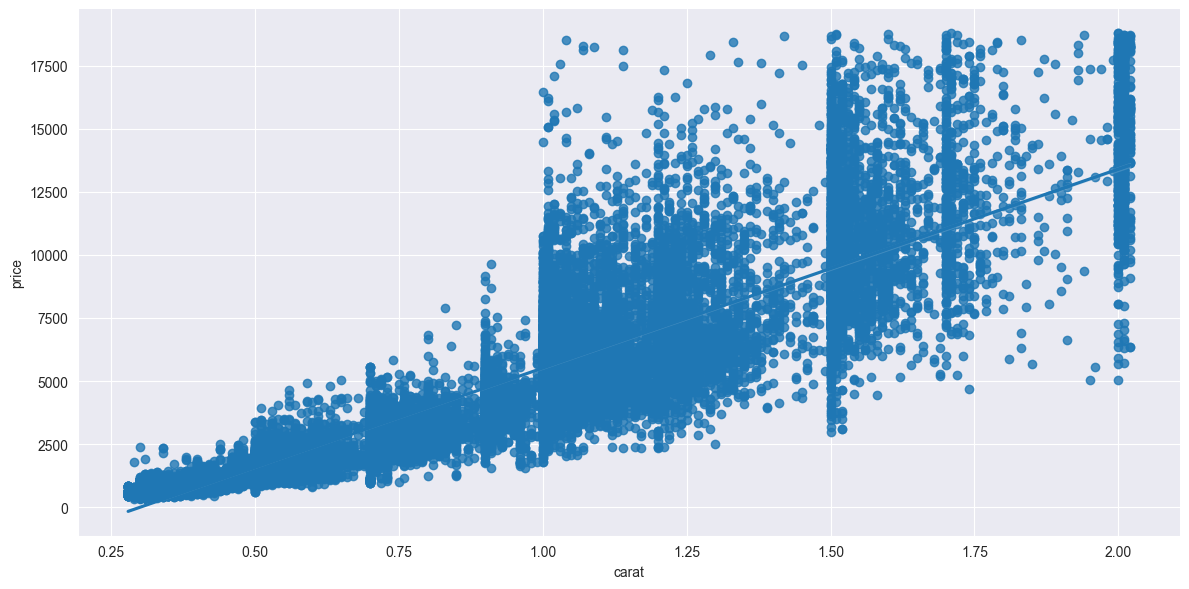

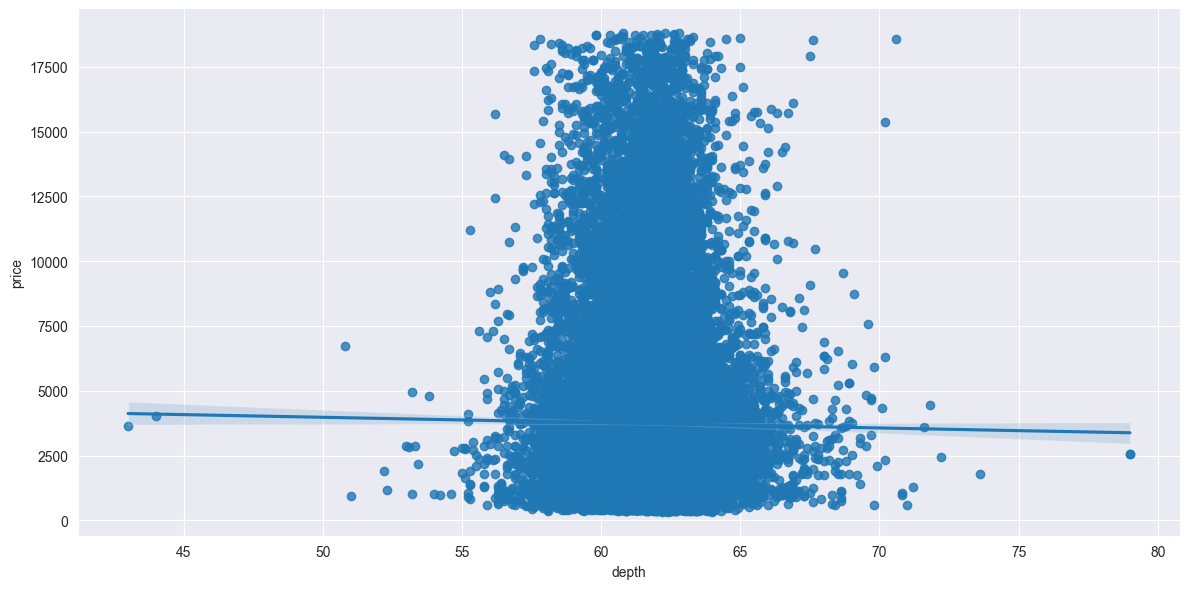

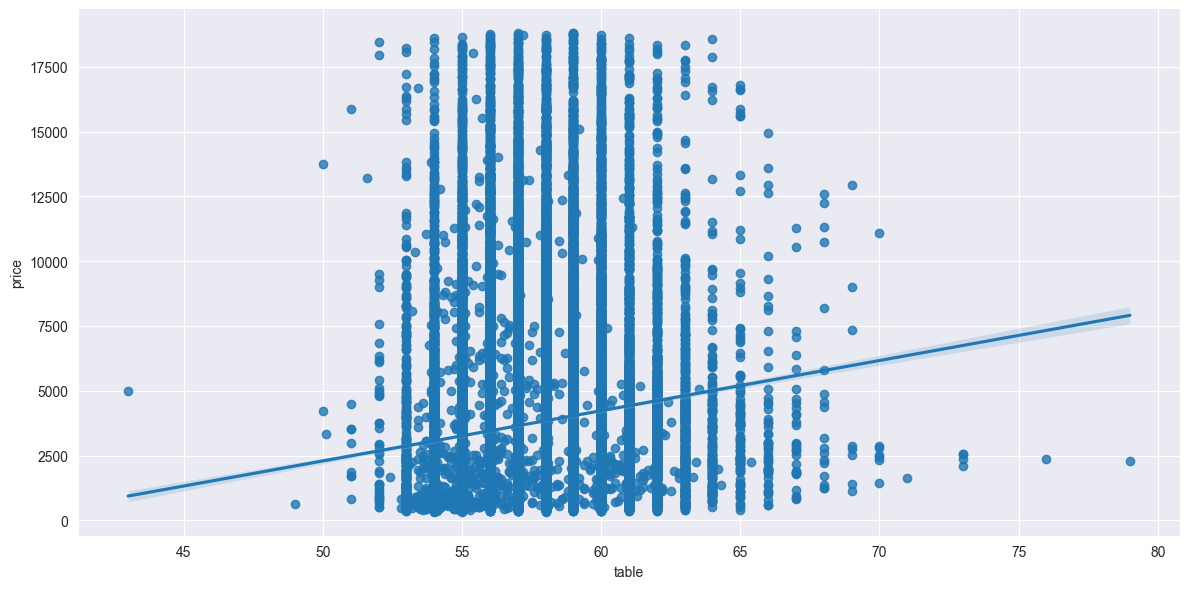

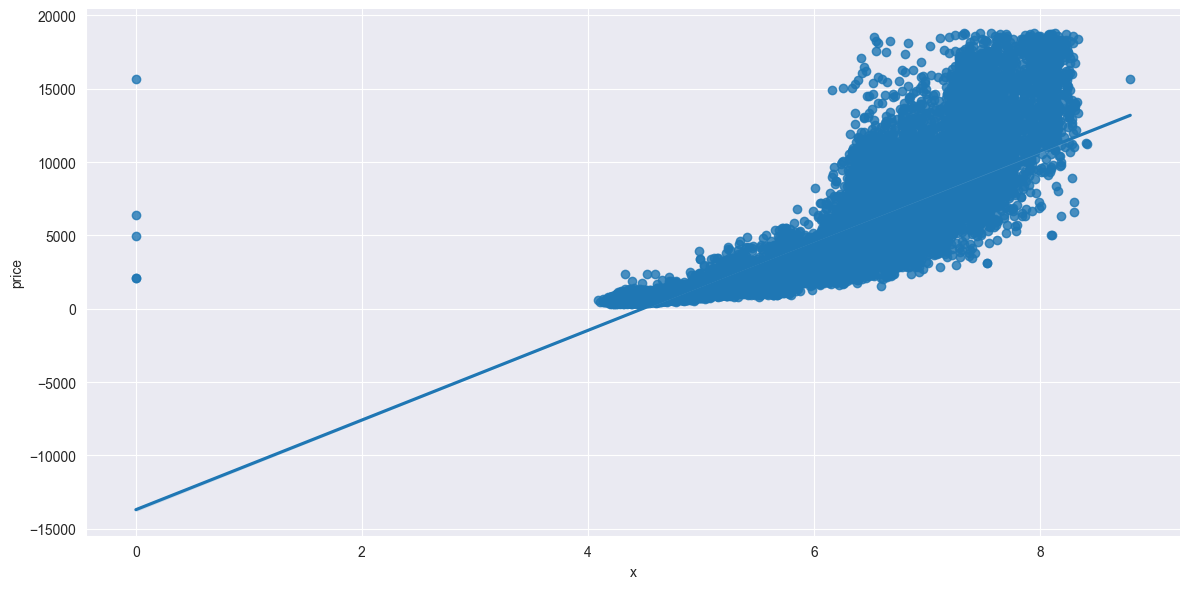

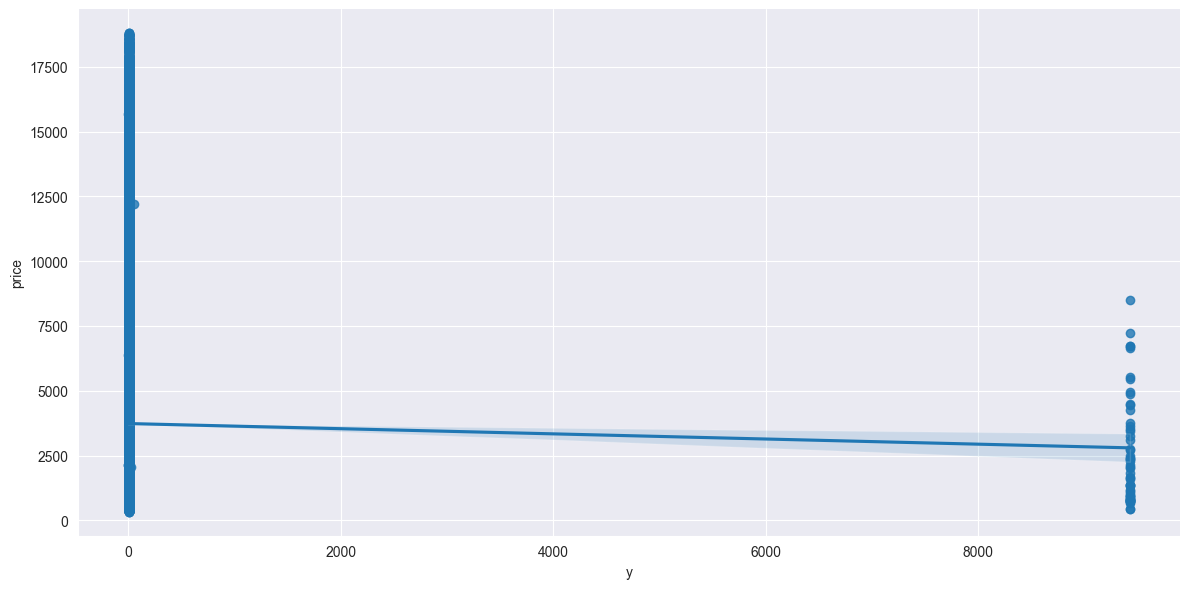

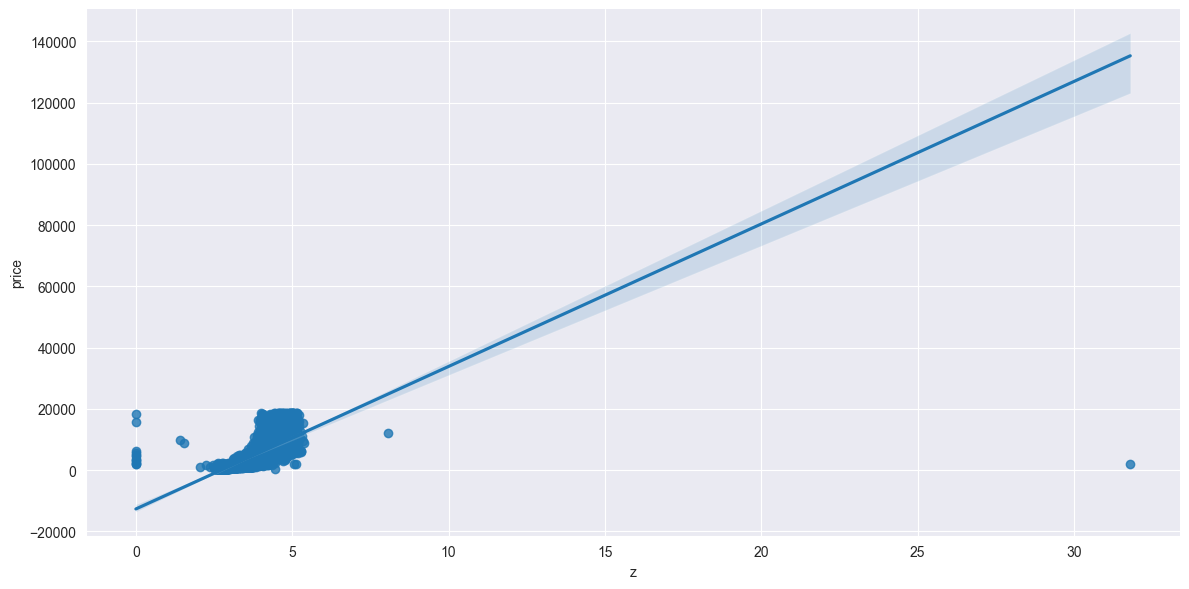

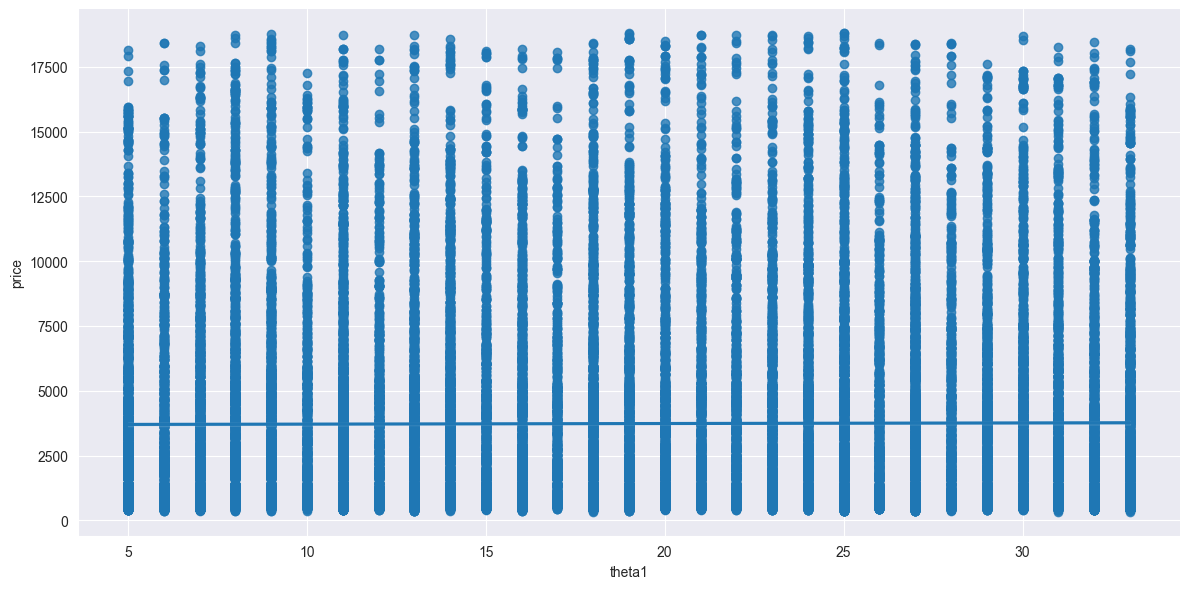

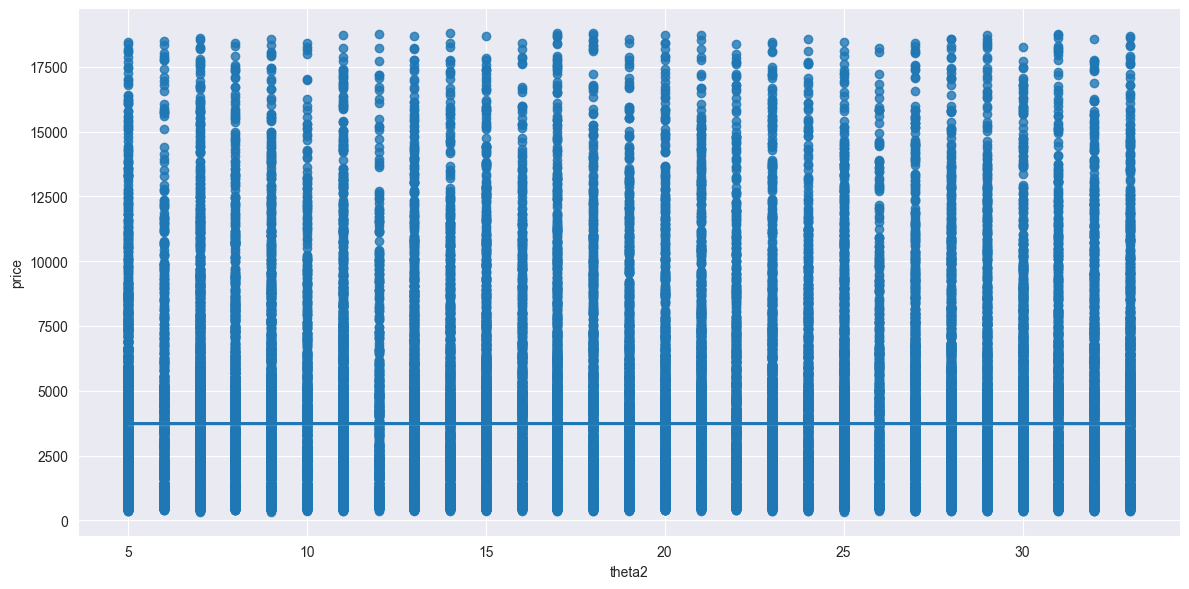

In [8]:
for col in ['carat','depth','table','x','y','z','theta1','theta2']:
    sns.lmplot(x=col, y='price', data=data_1, aspect=2, height=6)

По графикам видно, что действительно depth почти не влияет на цену, а carat, x, z имеют хорошую корреляцию с ценой, что еще раз проверим с помощью heat map далее.

Посмотрим на выбросы в некоторых признаках.

<Axes: >

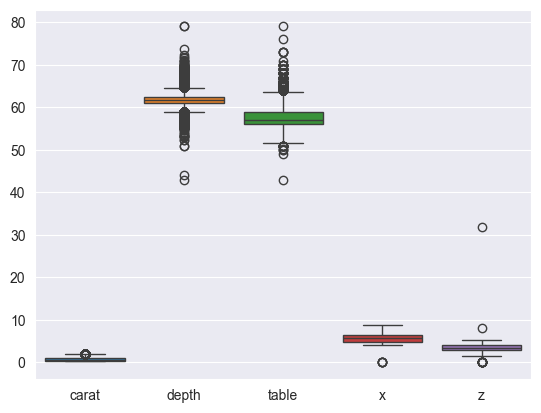

In [9]:
sns.boxplot(data=data_1[['carat', 'depth', 'table', 'x', 'z']])


Видно, что было бы хорошо избавиться от выбросов в depth, table и z.

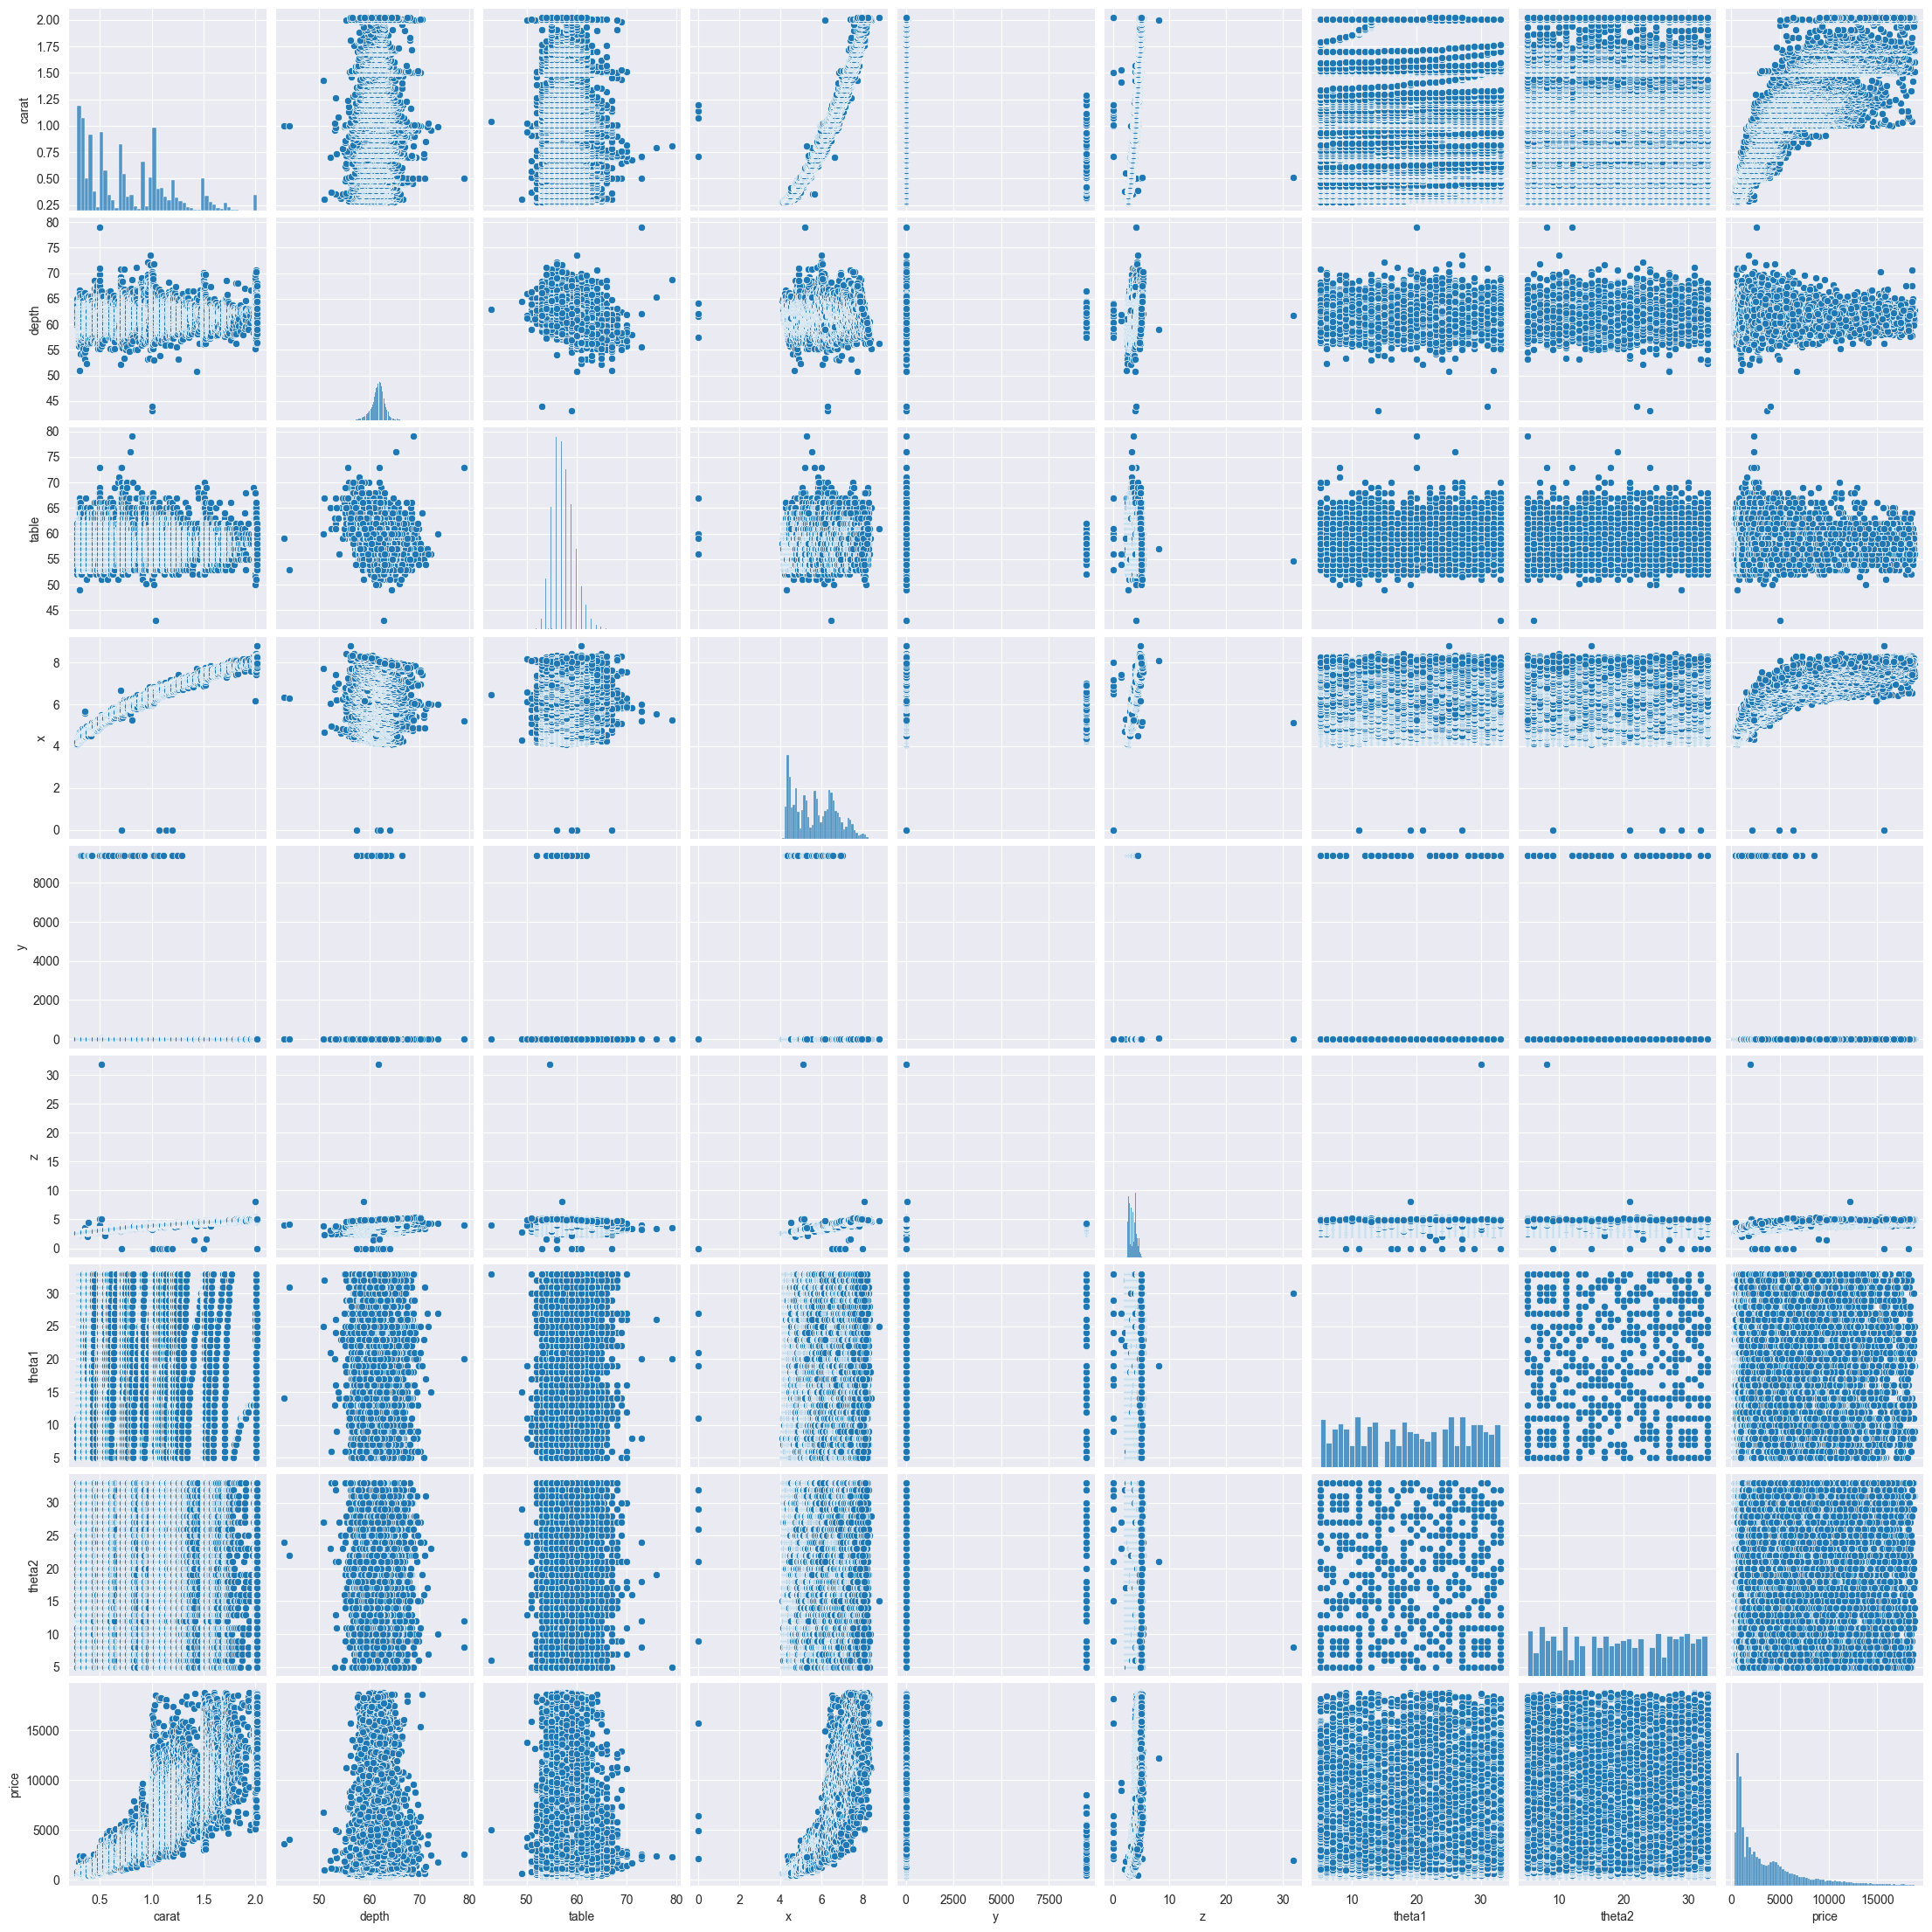

In [10]:
sns.pairplot(data_1.select_dtypes(include=[np.number]))

<Axes: >

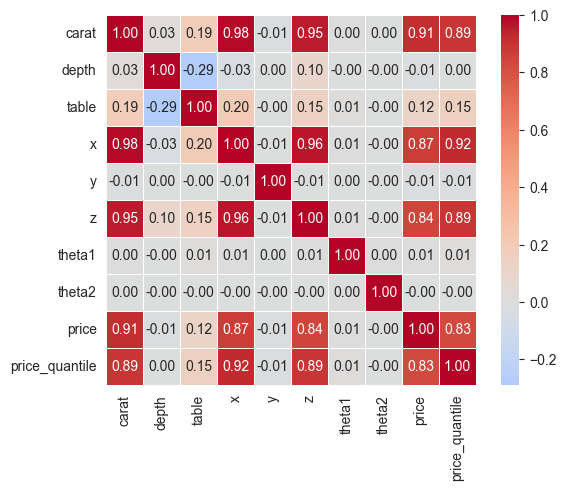

In [11]:
sns.heatmap(data_1.corr(), annot=True, cmap='coolwarm', center=0,
            square=True, fmt='.2f', linewidths=0.5)

Мы видим что признаки theta1 и theta2 не влияют на цену, а так же не коррелируют с другими признаками, значит их можно исключить из датасета.  
Также параметр y состоит из выбросов, так как имеет слишком маленькие или слишком большие значения для параметра, определяющего размер. Еще он ни с чем не коррелирует, значит его можно удалить. И хорошей идеей будет объединить параметры x и z в один, так как они имеют очень высокий коэффициент корреляции.

Удалим price_quantile, который использовали для анализа.

In [12]:
data_1.drop('price_quantile', axis=1, inplace=True)

Теперь посмотрим на категориальные признаки.

In [13]:
data_2.head()

,cut,color,clarity,price
id,,,,
17044,Ideal,F,VVS2,612
30625,Ideal,I,VS1,448
17043,'Very Good',F,IF,612
37947,'Very Good',E,VS2,487
30626,Ideal,I,VS1,448


In [14]:
data_2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 40453 entries, 17044 to 24111
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   cut      40453 non-null  object
 1   color    40453 non-null  object
 2   clarity  40389 non-null  object
 3   price    40453 non-null  int64 
dtypes: int64(1), object(3)
memory usage: 1.5+ MB


<Figure size 640x480 with 0 Axes>

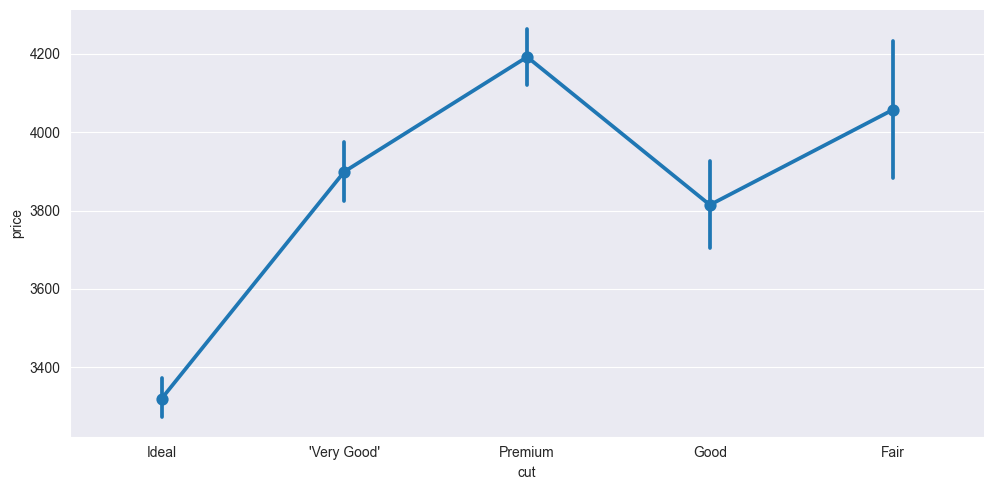

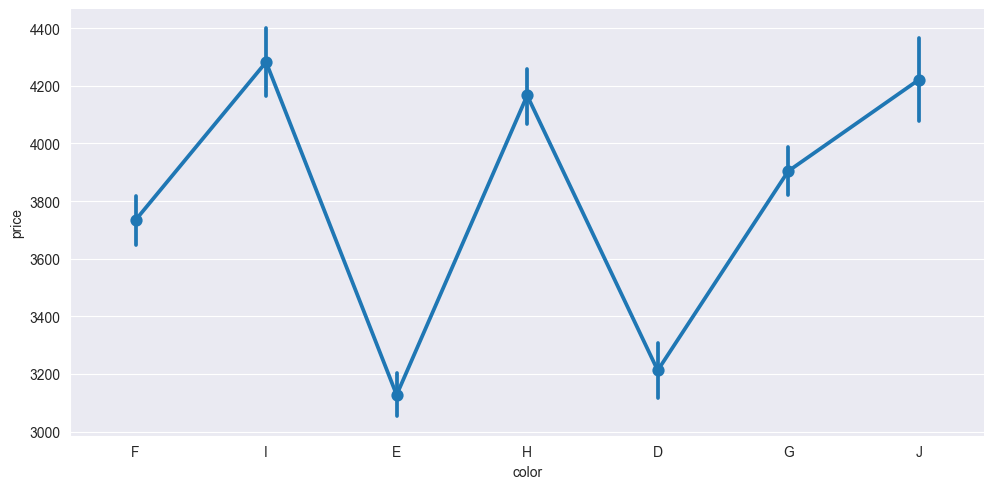

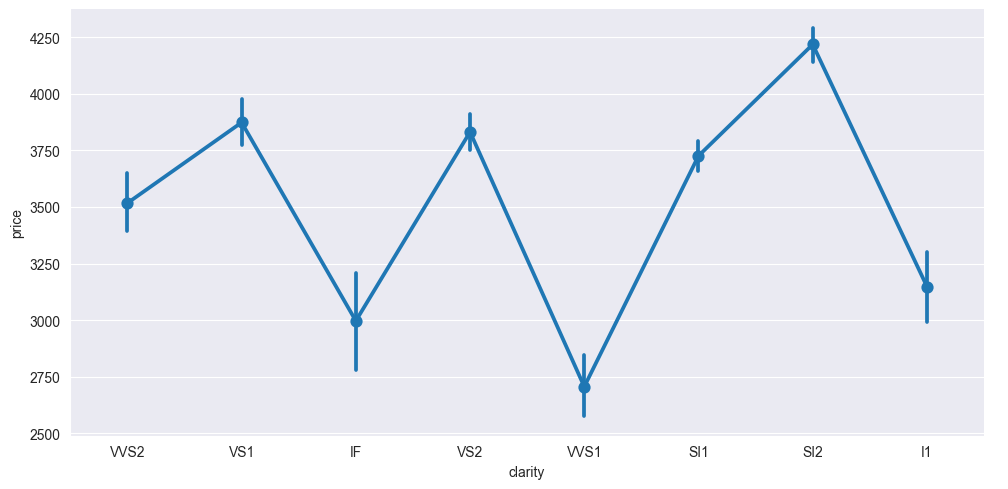

In [5]:
for i, col in enumerate(['cut','color','clarity']):
    plt.figure(i)
    sns.catplot(x=col, y='price', data=data_2, kind='point', aspect=2)

Видно, что цена имеет странную зависимость от качества огранки. При большем качестве, во многих случаях цена уменьшается. Скорее всего это из-за влияния других признаков, например маленького веса и размера у качественных алмазов. То же можно сказать и про признак чистоты. Проверим это, добавив новый признак, отображающий цену с учетом веса и размера камня.

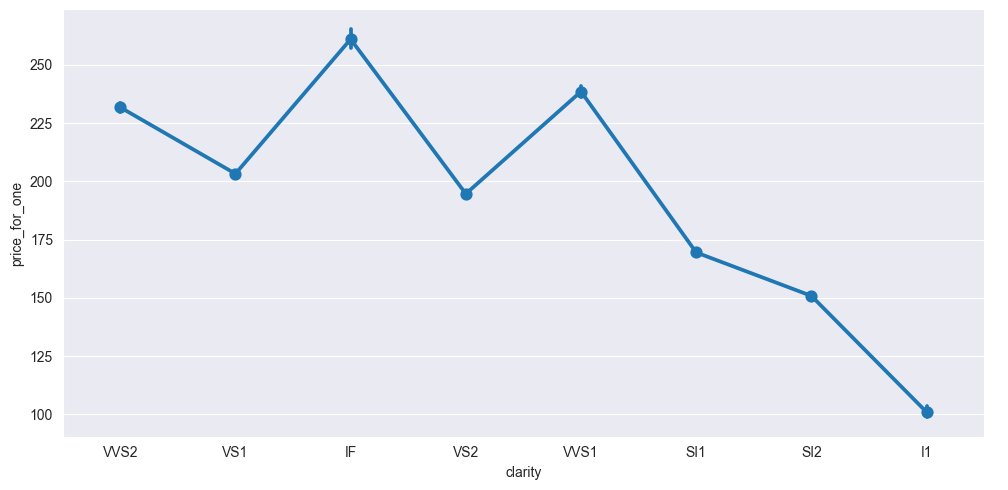

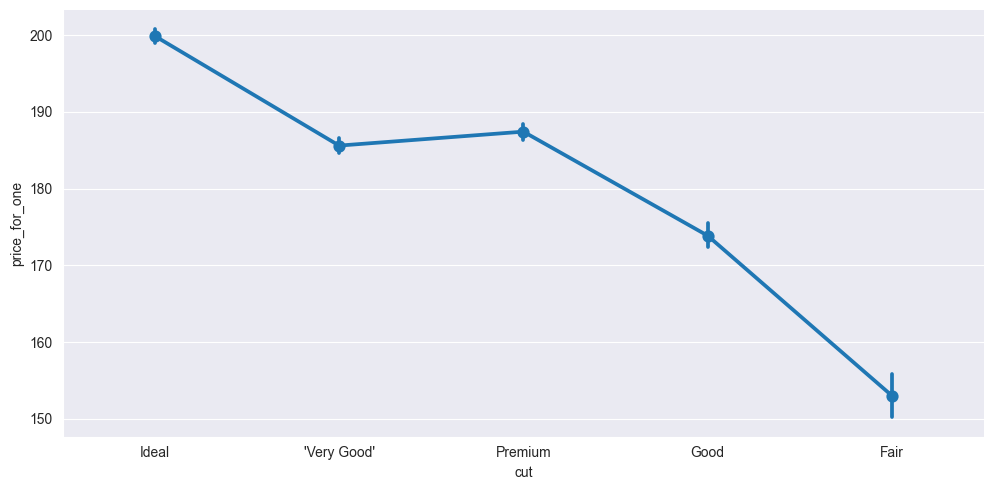

In [6]:
data['price_for_one']=data['price']/data['carat']/data['x']/data['z']
sns.catplot(x='clarity', y='price_for_one', data=data, kind='point', aspect=2)
sns.catplot(x='cut', y='price_for_one', data=data, kind='point', aspect=2)

Наши предположения подтвердились, значит все же данные признаки влияют на цену по своим категориям - от большего к меньшему как и должны. Впоследствии заменим их на числовые значения в порядке возрастания, где больше - лучше, меньше - хуже. То есть Ideal - 5, 'Very Good' - 3, Premium cut - 4, Good - 2, Fair - 1. И IF - 8, WS1 - 7, WS2 - 6, VS1 - 5, VS2 - 4, SI1 - 3, SI2 - 2, I1 - 1.

В конце удалим признак, который мы создали только для анализа. Это price_for_one.

In [7]:
data.drop(['price_for_one'], axis=1, inplace=True)

### Preprocessing (подготовка данных)

 В этом разделе вам необходимо реализовать подготовку ваших данных, в том числе заполнение пропусков, фильтрацию выбросов, кодирование категориальных признаков и т.д. В этот же раздел включите любые операции над данными, которые сочтете нужными.

Начнем с числовых признаков

In [8]:
# preprocessing pipeline
data_1.head()

,carat,depth,table,x,y,z,theta1,theta2,price
id,,,,,,,,,
17044,0.28,61.6,55.0,4.22,4.26,2.61,5,5,612
30625,0.28,62.5,54.0,4.18,4.23,2.63,5,6,448
17043,0.28,62.2,55.0,4.23,4.26,NaN,5,7,612
37947,0.28,63.0,59.0,4.11,4.15,2.60,5,8,487
30626,0.28,62.4,54.0,4.18,4.19,2.61,5,9,448


In [9]:
data_1.isna().sum()

carat      0
depth     57
table      0
x         48
y         60
z         42
theta1     0
theta2     0
price      0
dtype: int64

Пропущенных значений не много. Избавимся от выбросов, заменив их на пустые значения, а затем заполним все пустые средним.

In [10]:
for i in ['table','z']:
    Q1 = data_1[i].quantile(0.25)
    Q3 = data_1[i].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    data_1[i] = data[i].apply(lambda x: None if x < lower_bound or x > upper_bound else x)

In [11]:
data_1['table']=data_1['table'].fillna(data_1['table'].mean())
data_1['x']=data_1['x'].fillna(data_1['x'].mean())
data_1['z']=data_1['z'].fillna(data_1['z'].mean())

Теперь удалим ненужные признаки(theta1,theta2,y,depth) и объединим x и z в один.

In [12]:
data_1.drop(['theta1','theta2','y','depth'], axis=1, inplace=True)

In [13]:
data_1.head()

,carat,table,x,z,price
id,,,,,
17044,0.28,55.0,4.22,2.610000,612
30625,0.28,54.0,4.18,2.630000,448
17043,0.28,55.0,4.23,3.523633,612
37947,0.28,59.0,4.11,2.600000,487
30626,0.28,54.0,4.18,2.610000,448


In [14]:
data_1['xz'] = data_1['x']*data_1['z']
data_1.drop(['x','z'], axis=1, inplace=True)

In [15]:
data_1.head()

,carat,table,price,xz
id,,,,
17044,0.28,55.0,612,11.014200
30625,0.28,54.0,448,10.993400
17043,0.28,55.0,612,14.904967
37947,0.28,59.0,487,10.686000
30626,0.28,54.0,448,10.909800


Теперь посмотрим на категориальные признаки

In [16]:
data_2.head()

,cut,color,clarity,price
id,,,,
17044,Ideal,F,VVS2,612
30625,Ideal,I,VS1,448
17043,'Very Good',F,IF,612
37947,'Very Good',E,VS2,487
30626,Ideal,I,VS1,448


In [17]:
data_2.isna().sum()

cut         0
color       0
clarity    64
price       0
dtype: int64

Заменим значения в cut и clarity на числа, обозначающие степень ценности определенной категории.

In [18]:
data_2['cut']=data_2['cut'].map({'Ideal':5,'Premium cut':4,"'Very Good'":3, 'Good':2,'Fair':1})

In [19]:
data_2['clarity']=data_2['clarity'].map({'IF': 8, 'VVS1': 7, 'VVS2': 6, 'VS1': 5, 'VS2': 4, 'SI1': 3, 'SI2': 2, 'I1': 1})

In [20]:
data_2['cut']=data_2['cut'].fillna(data_2['cut'].mean())
data_2['clarity']=data_2['clarity'].fillna(data_2['clarity'].mean())

Для признака color выполним one-hot-encoding

In [21]:
data_2=pd.get_dummies(data_2, columns = ['color'], drop_first=True)

In [22]:
data_2.head()

,cut,clarity,price,color_E,color_F,color_G,color_H,color_I,color_J
id,,,,,,,,,
17044,5.0,6.0,612,False,True,False,False,False,False
30625,5.0,5.0,448,False,False,False,False,True,False
17043,3.0,8.0,612,False,True,False,False,False,False
37947,3.0,4.0,487,True,False,False,False,False,False
30626,5.0,5.0,448,False,False,False,False,True,False


Теперь объединим оба типа признаков обратно в один датасет

In [23]:
data = pd.concat([data_1.drop('price',axis = 1), data_2], axis=1)

In [24]:
data.head()

,carat,table,xz,cut,clarity,price,color_E,color_F,color_G,color_H,color_I,color_J
id,,,,,,,,,,,,
17044,0.28,55.0,11.014200,5.0,6.0,612,False,True,False,False,False,False
30625,0.28,54.0,10.993400,5.0,5.0,448,False,False,False,False,True,False
17043,0.28,55.0,14.904967,3.0,8.0,612,False,True,False,False,False,False
37947,0.28,59.0,10.686000,3.0,4.0,487,True,False,False,False,False,False
30626,0.28,54.0,10.909800,5.0,5.0,448,False,False,False,False,True,False


### Model & training (Выбор модели и её обучение)

В этом разделе описываете модель и ставите эксперименты по обучению.

Если вы ставили много экспериментов, приведите их в хронологическом порядке чтобы мы увидели эволюцию ваших рассуждений.

#### Эксперимент 1

Сначала проверим обычную линейную регрессию

In [25]:
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression, ElasticNet, Ridge, HuberRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

X_train, X_test , y1_train, y1_test = train_test_split(data.drop('price', axis=1), data.price, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
model1 = RandomForestRegressor(n_estimators=100, random_state=42)
model1.fit(X_train, y1_train)

y1_pred = model1.predict(X_test)


#### Эксперимент 2

Еще поверим регрессию Хубера

In [35]:
from sklearn.neighbors import KNeighborsRegressor
X_train, X_test , y2_train, y2_test = train_test_split(data.drop('price', axis=1), data.price, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
model2 = KNeighborsRegressor(n_neighbors=5)
model2.fit(X_train, y2_train)

y2_pred = model2.predict(X_test)

#### Эксперимент 3

### Evaluation (оценка качества модели)

В этом разделе проводите оценку качества вашей итоговой модели. 

Для линейной регрессии:

In [36]:
r2 = r2_score(y1_test, y1_pred)
print('R²: ', r2)

mse = mean_squared_error(y1_test, y1_pred)
print('MSE: ', mse)

rmse = np.sqrt(mse)
print('RMSE: ', rmse)

mae = np.abs(y1_test - y1_pred).mean()
print('MAE: ', mae)


R²:  0.9787127854760695
MSE:  282253.1110236109
RMSE:  531.2749862581627
MAE:  281.26842470518875


Для регрессии Хубера:

In [37]:
r2 = r2_score(y2_test, y2_pred)
print('R²: ', r2)

mse = mean_squared_error(y2_test, y2_pred)
print('MSE: ', mse)

rmse = np.sqrt(mse)
print('RMSE: ', rmse)

mae = np.abs(y2_test - y2_pred).mean()
print('MAE: ', mae)

R²:  0.9658471422895532
MSE:  452842.2602348288
RMSE:  672.9355542953789
MAE:  351.9507848226425


Линейная регрессия объясняет немного большую часть данных, а регрессия Хубера имеет меньшую ошибку.

### Conclusion (Выводы)

В этом разделе описываете полученные результаты и проводите анализ выполненной работы. 
Что получилось / не получилось и почему?

В результате выполнения данной работы, получилось построить модель, которая предсказывает стоимость алмаза по заданным характеристикам. Модель имеет неплохую точность, которая, тем не менее, ограничена использованием именно линейной модели. В ходе работы я научился работать с числовыми и категориальными признаками. С помощью анализа графиков и тепловой карты мне удалось определить наиболее значимые признаки, найти корреляцию между ними. Также удалось обработать категориальные признаки, превратив их в числовые значения, или бинарные принадлежности категориям. Важной является также работа с выбросами и пропущенными значениями, которые были заполнены с помощью средних значений, чтобы не вызывать отклонение модели в одну из сторон.

### Предсказание цен для тестового датасета Kaggle:

In [38]:
test_data = pd.read_csv('test.csv', index_col=0)
test_ids = test_data.index
for i in ['table', 'z']:
    Q1 = test_data[i].quantile(0.25)
    Q3 = test_data[i].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    test_data[i] = test_data[i].apply(lambda x: None if x < lower_bound or x > upper_bound else x)

test_data['table'] = test_data['table'].fillna(test_data['table'].mean())
test_data['x'] = test_data['x'].fillna(test_data['x'].mean())
test_data['z'] = test_data['z'].fillna(test_data['z'].mean())

test_data.drop(['theta1', 'theta2', 'y', 'depth'], axis=1, inplace=True)

test_data['xz'] = test_data['x'] * test_data['z']
test_data.drop(['x', 'z'], axis=1, inplace=True)

test_data['cut'] = test_data['cut'].map({'Ideal': 5, 'Premium cut': 4, "'Very Good'": 3, 'Good': 2, 'Fair': 1})
test_data['clarity'] = test_data['clarity'].map(
    {'IF': 8, 'VVS1': 7, 'VVS2': 6, 'VS1': 5, 'VS2': 4, 'SI1': 3, 'SI2': 2, 'I1': 1})

test_data['cut'] = test_data['cut'].fillna(test_data['cut'].mean())
test_data['clarity'] = test_data['clarity'].fillna(test_data['clarity'].mean())

test_data = pd.get_dummies(test_data, columns=['color'], drop_first=True)




In [39]:
test_data = test_data[data.drop('price', axis=1).columns]

In [40]:
test_data=scaler.transform(test_data)

In [43]:
yy_pred = model1.predict(test_data)

In [44]:
submission = pd.DataFrame({
    'id': test_ids,
    'price': yy_pred
})

submission.to_csv('submission.csv', index=False)